# Centre de donnees : redresseur a diodes, onduleur V/f, batterie et groupe de secours

Un centre de donnees alimente par le reseau MT, avec son groupe electrogene de
secours. Le site est assemble de **blocs elementaires**, chacun un `Element` de
`g2egrid` qui sert aussi bien a la simulation **non lineaire** qu'au modele d'etat
**linearise** :

| Bloc | Classe | Role |
|---|---|---|
| transformateur | `Transformer` | MT/BT (existant) |
| redresseur a diodes + capacites | `RedresseurDiode`, capacite du bus alternatif, `BusDC` | pont triphase, modele moyen dq ; la capacite alternative est celle du bus `[4]`, la continue celle du bus `[10]` |
| onduleur V/f constants | `OnduleurVF` | tension et frequence de consigne, sans statisme, slack de l'ilot IT |
| charge IT | `ChargeACPref` | puissance constante, entree `p_ref` |
| DC/DC + batterie | `BatterieDCDC` | soutien du bus continu, lissage, etat de charge |
| groupe de secours | `GroupeElectrogene` | alternateur + moteur diesel + arbre elastique a deux masses |

```
GRID --- L_AMONT --- [2] ---+--- T_DC --- [4] RED === bus continu [10] === OND --- [5] IT
 (20 kV)             MT     |                          |
                            |                         BAT
                            +--- T_GE --- [3] GE (diesel + alternateur)
```

**Question posee** : que subit l'arbre du groupe electrogene quand il alimente seul
le site, face a une charge informatique qui varie de plusieurs dizaines de pour
cent en quelques secondes ? Le notebook va de la construction du reseau a un bilan
de **fatigue mecanique** de l'accouplement (comptage rainflow, courbe S-N, regle de
Miner).

Duree d'execution : plusieurs minutes (trois simulations non lineaires de 2 a 10
minutes de temps simule). Les durees se reglent dans la premiere cellule de code.

In [1]:
import sys
import pathlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.linalg as sl
from IPython.display import display

# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

from g2egrid.datacenter import (  # noqa: E402
    NOMS,
    courbe_charge_ia,
    reseau_datacenter,
    scenario_perte_reseau,
)
from g2egrid.fatigue import (  # noqa: E402
    ARBRE_DEFAUT,
    COURBE_ACIER_ARBRE,
    couple_base,
    evaluer_fatigue,
    tension_cisaillement,
)
from g2egrid.temporel import Courbe, ModeleNonLineaire, simuler_lineaire  # noqa: E402

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.figsize": (10, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False})

# ---- durees de simulation (secondes de temps SIMULE) ----
DUREE_ILOT = 600.0        # site isole, groupe seul : 10 minutes
DUREE_TRANSITION = 240.0  # perte du reseau puis reprise par le groupe
DT = 0.05                 # pas d'echantillonnage des courbes et des sorties
SN_GROUPE = 2.5e6         # puissance apparente du groupe [VA]

## 1. Le reseau type

`reseau_datacenter()` construit le site, resout le load flow **mixte alternatif /
continu** (le pont de diodes tient la tension du bus continu, l'onduleur forme son
ilot alternatif) puis l'equilibre de chaque element. Base systeme : 5 MVA ; charge
IT nominale : 1,5 MW ; groupe : 2,5 MVA.

In [2]:
t0 = time.time()
net = reseau_datacenter()
print(f"reseau construit et resolu en {time.time() - t0:.1f} s (compilation symbolique comprise)")
print("load flow converge :", net.lf.converged, "| residu du load flow :", f"{net.lf.mismatch:.1e}")

idx = net._bus_index()
bus = pd.DataFrame(
    {"bus": b, "Un [V]": net.bus_specs[b].Un, "|V| [pu]": abs(net.lf.V[i]),
     "angle [deg]": np.degrees(np.angle(net.lf.V[i]))}
    for b, i in sorted(idx.items())
)
display(bus.round(4).set_index("bus"))
print("tension du bus continu [10] :", round(net.v_dc[10], 4), "pu")

elems = pd.DataFrame(
    {"element": e.name, "classe": type(e).__name__, "bus": e.buses, "etats": len(e.states)}
    for e in net.elements
    if not type(e).__name__.startswith("Bus")
)
display(elems.set_index("element"))

reseau construit et resolu en 5.5 s (compilation symbolique comprise)
load flow converge : True | residu du load flow : 3.6e-15


,Un [V],|V| [pu],angle [deg]
bus,,,
1,20000.0,1.0000,0.0000
2,20000.0,0.9982,-0.3330
3,400.0,1.0000,-0.2675
4,400.0,0.9911,-2.7912
5,400.0,1.0000,0.0000


tension du bus continu [10] : 1.0 pu


,classe,bus,etats
element,,,
GRID,IB,[1],3
L_AMONT,Line,"[1, 2]",2
T_DC,Transformer,"[2, 4]",2
RED,RedresseurDiode,"[4, 10]",1
OND,OnduleurVF,"[5, 10]",13
IT,ChargeACPref,[5],2
BAT,BatterieDCDC,[10],3
T_GE,Transformer,"[3, 2]",2
GE,GroupeElectrogene,[3],22


In [3]:
def sortie(net, nom, s):
    """Une sortie de service d'un element, a l'equilibre."""
    el = next(e for e in net.elements if e.name == nom)
    y = el.compiled().h(el.x0, el.z0, el.u0, el.p)
    return float(y[el.n_port_signaux() + el.svc_outputs.index(s)])

Sb = net.Sb
bilan = pd.Series({
    "charge IT [kW]": sortie(net, "IT", "p") * Sb / 1e3,
    "onduleur : puissance AC fournie [kW]": sortie(net, "OND", "P") * 0.4 * Sb / 1e3,
    "redresseur : puissance AC absorbee [kW]": sortie(net, "RED", "p") * Sb / 1e3,
    "groupe en attente [kW]": sortie(net, "GE", "P") * 0.5 * Sb / 1e3,
    "batterie [kW]": sortie(net, "BAT", "p") * Sb / 1e3,
})
display(bilan.round(1).to_frame("a l'equilibre"))

red = next(e for e in net.elements if e.name == "RED")
idc, vdc = red.x0[0], net.v_dc[10]
rcom = np.pi * red.pdict["Xcom"] / 6  # chute de commutation, pu continu
p_ac = sortie(net, "RED", "p") / red.pdict["kS"]
print(f"pont : P_ac = {p_ac:.4f} pu, P_dc = vdc.idc = {vdc * idc:.4f} pu -> pertes {100 * (1 - vdc * idc / p_ac):.2f} %")
print(f"       calage : kv = {red.pdict['kv']:.4f} ; Vr = kv.|V| = {sortie(net, 'RED', 'vr'):.4f} pu > vdc = {vdc:.4f} pu")
print(f"       commutation : Rcom = {rcom:.4f} pu, tan(phi) = {red.pdict['tphi']:.4f} -> Q = {sortie(net, 'RED', 'q') * Sb / 1e3:.1f} kvar")

,a l'equilibre
charge IT [kW],1500.0
onduleur : puissance AC fournie [kW],1503.4
redresseur : puissance AC absorbee [kW],1520.4
groupe en attente [kW],50.0
batterie [kW],0.0


pont : P_ac = 0.7602 pu, P_dc = vdc.idc = 0.7573 pu -> pertes 0.38 %
       calage : kv = 1.0247 ; Vr = kv.|V| = 1.0157 pu > vdc = 1.0000 pu
       commutation : Rcom = 0.0157 pu, tan(phi) = 0.1455 -> Q = 221.2 kvar


### Modes du modele linearise

Le meme equilibre donne le modele d'etat `(A, B, C, D)`. Les modes qui comptent
pour le groupe : le **mode de torsion** de l'accouplement (`f_tors` = 25 Hz) et le
**mode electromecanique** du groupe sur le reseau, celui qu'une charge qui oscille
peut exciter.

In [4]:
ss = net.build_state_space()
print(ss, "| stable :", ss.is_stable())

w, vl, vr = sl.eig(ss.A, left=True, right=True)
lignes = []
for k in range(len(w)):
    if w[k].imag <= 0 or abs(w[k]) > 2 * np.pi * 200:  # modes de 0 a 200 Hz
        continue
    part = np.abs(vl[:, k] * vr[:, k])
    part /= part.sum()
    top = np.argsort(-part)[:3]
    lignes.append({
        "f [Hz]": abs(w[k].imag) / 2 / np.pi,
        "amortissement": -w[k].real / abs(w[k]),
        "sigma [1/s]": w[k].real,
        "etats dominants": ", ".join(ss.states[i] for i in top),
    })
modes = pd.DataFrame(lignes).sort_values("f [Hz]")
display(modes.round(3).head(14).set_index("f [Hz]"))
n_nuls = int(np.sum(np.abs(w) < 1e-6))
print(f"{n_nuls} modes nuls : l'etat de charge de la batterie, l'angle de l'onduleur, l'angle du bus infini")

<StateSpace 61 etats, 16 entrees, 55 sorties | max Re(lambda)=+0.000e+00> | stable : True


,amortissement,sigma [1/s],etats dominants
f [Hz],,,
1.056,0.591,-4.855,"GE.phi_fd, GE.efd, GE.e3"
3.091,0.204,-4.037,"GE.theta, GE.Dwe, GE.Dwr"
25.270,0.031,-4.962,"GE.dsh, GE.Dwr, GE.Dwe"
31.836,0.707,-200.036,"OND.ved, OND.M_VLd, OND.veq"
31.840,0.707,-199.968,"OND.M_VLq, OND.veq, OND.M_VLd"
40.055,0.056,-14.223,"bus10.v, RED.idc, T_DC.i_d"
49.937,0.032,-10.036,"GE.phi_q, GE.phi_d, T_GE.i_q"


3 modes nuls : l'etat de charge de la batterie, l'angle de l'onduleur, l'angle du bus infini


## 2. Les blocs a l'epreuve

Trois verifications ponctuelles, avant de simuler. Le **redresseur** : bilan de
puissance exact (ce qui entre en alternatif sort en continu, aux pertes de `Rdc` pres)
et blocage des diodes quand la batterie releve le bus continu. L'**onduleur** : tension
et frequence de l'ilot IT insensibles a la charge. La **batterie** : inerte en veille,
elle ne se vide pas.

residu d'equilibre du modele non lineaire : (3.434823831268084e-10, 1.6400075741884734e-14)


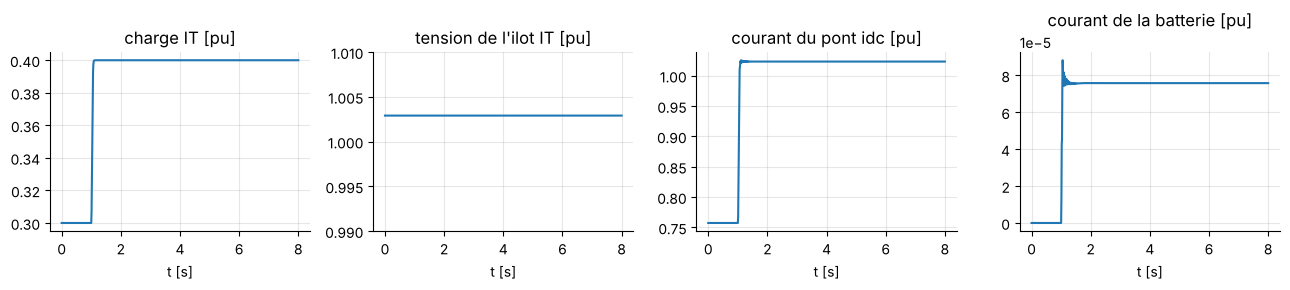

frequence de l'ilot : ecart max 0.0e+00 pu
tension de l'ilot : ecart max 2.5e-07 pu
batterie : courant max 8.8e-05 pu -> inerte au-dessus de v_ref


In [5]:
m = ModeleNonLineaire(net)
print("residu d'equilibre du modele non lineaire :", m.residu_equilibre())

# un echelon de +0,10 pu de charge IT a t = 1 s, rampe de 50 ms
from g2egrid.temporel import Evenement
tt = np.linspace(0, 8, 801)
tr = m.simuler((0, 8), uext_fn=m.scenario(Evenement(1.0, "IT.p_ref", 0.10, "rampe", 0.05)),
               t_eval=tt, rtol=1e-6, atol=1e-8, sorties=["OND.Vt", "OND.w", "IT.p"])

fig, ax = plt.subplots(1, 4, figsize=(13, 3))
ax[0].plot(tt, tr.sorties["IT.p"]); ax[0].set_title("charge IT [pu]")
ax[1].plot(tt, tr.sorties["OND.Vt"]); ax[1].set_title("tension de l'ilot IT [pu]")
ax[1].set_ylim(0.99, 1.01)
ax[2].plot(tt, tr.etat("RED.idc")); ax[2].set_title("courant du pont idc [pu]")
ax[3].plot(tt, tr.etat("BAT.i")); ax[3].set_title("courant de la batterie [pu]")
for a in ax: a.set_xlabel("t [s]")
plt.tight_layout(); plt.show()
print(f"frequence de l'ilot : ecart max {np.abs(tr.sorties['OND.w'] - 1).max():.1e} pu")
print(f"tension de l'ilot : ecart max {np.abs(tr.sorties['OND.Vt'] - tr.sorties['OND.Vt'][0]).max():.1e} pu")
print(f"batterie : courant max {np.abs(tr.etat('BAT.i')).max():.1e} pu -> inerte au-dessus de v_ref")

## 3. Une courbe de charge de plusieurs minutes

`ChargeACPref` a une entree absolue `IT.p_ref`. `Courbe` la pilote par une serie
`(t, P)` : ici un profil **synthetique** d'entrainement d'IA (a remplacer par une
mesure : `Courbe("IT.p_ref", t_mesure, P_mesure)`). Il reproduit les traits que
les exploitants decrivent : charge stable au repos, puis regime **alterne** calcul /
communication toutes les 4 s (creneaux de +-25 %), avec des **sauvegardes**
(checkpoints) toutes les 2 minutes qui font chuter la charge de 60 % pendant 6 s.

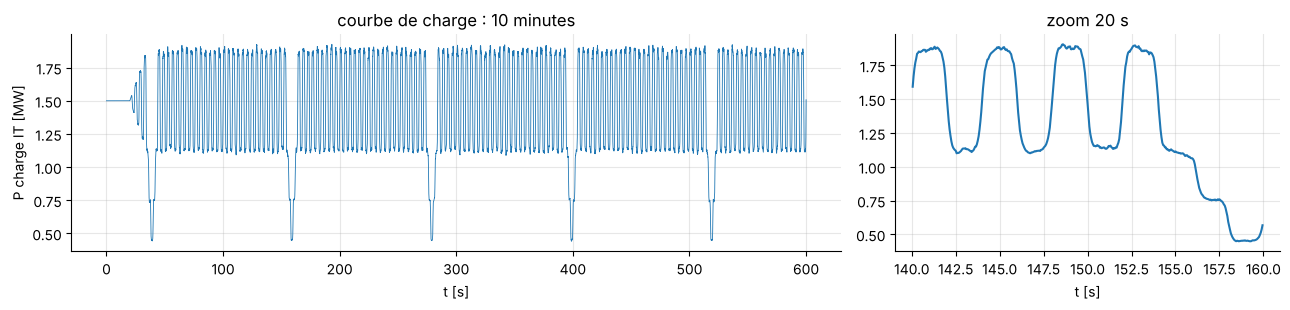

P moyenne 1.45 MW, min 0.44 MW, max 1.93 MW


In [6]:
t_ilot = np.arange(0.0, DUREE_ILOT + DT / 2, DT)
P_it = courbe_charge_ia(t_ilot, P_moy=0.30, amplitude=0.25, periode=4.0,
                        t_debut=20.0, rampe=15.0, intervalle_ckpt=120.0,
                        duree_ckpt=6.0, profondeur_ckpt=0.6, bruit=0.01, graine=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(t_ilot, P_it * 5, lw=0.6); ax[0].set_xlabel("t [s]"); ax[0].set_ylabel("P charge IT [MW]")
ax[0].set_title(f"courbe de charge : {DUREE_ILOT / 60:.0f} minutes")
z = (t_ilot > 140) & (t_ilot < 160)
ax[1].plot(t_ilot[z], P_it[z] * 5); ax[1].set_xlabel("t [s]"); ax[1].set_title("zoom 20 s")
plt.tight_layout(); plt.show()
print(f"P moyenne {P_it.mean() * 5:.2f} MW, min {P_it.min() * 5:.2f} MW, max {P_it.max() * 5:.2f} MW")

## 4. Le site isole, alimente par le groupe : lineaire contre non lineaire

`reseau_datacenter(reseau_amont=False)` retire le reseau amont : le groupe est le slack
et porte toute la charge. C'est l'etat de regime **apres** la perte du reseau, et
l'equilibre autour duquel le modele linearise decrit le site alimente par le groupe.

La meme courbe `P_it` pilote les deux modeles. Le non lineaire est la reference ; le
linearise (discretisation exacte, pas de 50 ms) coute une fraction de seconde.

In [7]:
net_i = reseau_datacenter(reseau_amont=False)
m_i = ModeleNonLineaire(net_i)
print("residu d'equilibre :", m_i.residu_equilibre())
ge_i = next(e for e in net_i.elements if e.name == "GE")
print(f"groupe seul : P = {sortie(net_i, 'GE', 'P') * 0.5 * net_i.Sb / 1e6:.2f} MW, "
      f"couple d'arbre = {sortie(net_i, 'GE', 'C_arbre'):.3f} pu ; plage du moteur [0, {ge_i.pdict['Fmax']}] pu")

sc_i = m_i.scenario(Courbe("IT.p_ref", t_ilot, P_it))
SORTIES = ["GE.C_arbre", "GE.P", "GE.Omega", "IT.p"]

t0 = time.time()
tr_nl = m_i.simuler((0, DUREE_ILOT), uext_fn=sc_i, t_eval=t_ilot, rtol=1e-4, atol=1e-6, sorties=SORTIES)
t_nl = time.time() - t0
t0 = time.time()
tr_li = simuler_lineaire(m_i, t_ilot, sc_i, sorties=SORTIES)
t_li = time.time() - t0
print(f"non lineaire : {t_nl:.0f} s de calcul ({tr_nl.n_solves} resolutions) ; "
      f"lineaire : {t_li:.2f} s ; rapport {t_nl / t_li:.0f}")
print("basculements de mode (butee de carburant...) :", tr_nl.basculements)

residu d'equilibre : (3.976894373930322e-12, 0.0)
groupe seul : P = 1.52 MW, couple d'arbre = 0.621 pu ; plage du moteur [0, 0.88] pu


non lineaire : 249 s de calcul (360996 resolutions) ; lineaire : 0.22 s ; rapport 1118
basculements de mode (butee de carburant...) : []


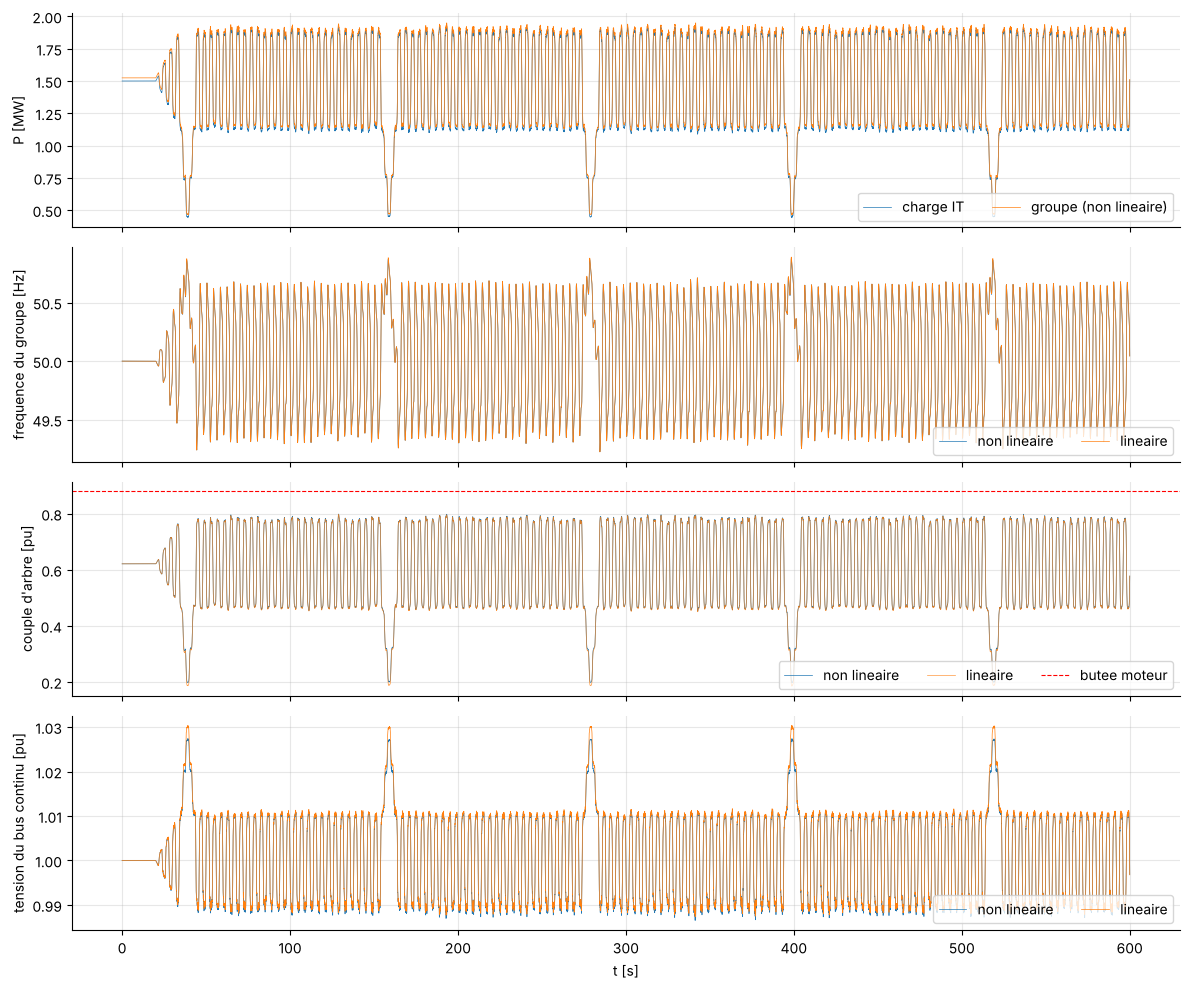

,excursion NL (crete a crete),ecart max lin-NL,ecart / excursion [%]
grandeur,,,
couple d'arbre [pu],0.6017,0.0126,2.1022
vitesse [pu],0.0330,0.0003,0.8097
P groupe [pu],0.5951,0.0044,0.7407
tension continue [pu],0.0409,0.0030,7.3611


In [8]:
def courbes(tr, nom):
    return tr.sorties[nom]

fig, ax = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
ax[0].plot(t_ilot, P_it * 5, lw=0.5, label="charge IT")
ax[0].plot(t_ilot, courbes(tr_nl, "GE.P") * 2.5, lw=0.5, label="groupe (non lineaire)")
ax[0].set_ylabel("P [MW]"); ax[0].legend(loc="lower right", ncol=2)
ax[1].plot(t_ilot, courbes(tr_nl, "GE.Omega") * 50, lw=0.5, label="non lineaire")
ax[1].plot(t_ilot, courbes(tr_li, "GE.Omega") * 50, lw=0.5, label="lineaire")
ax[1].set_ylabel("frequence du groupe [Hz]"); ax[1].legend(loc="lower right", ncol=2)
ax[2].plot(t_ilot, courbes(tr_nl, "GE.C_arbre"), lw=0.5, label="non lineaire")
ax[2].plot(t_ilot, courbes(tr_li, "GE.C_arbre"), lw=0.5, label="lineaire", alpha=0.8)
ax[2].axhline(ge_i.pdict["Fmax"], color="r", ls="--", lw=0.8, label="butee moteur")
ax[2].set_ylabel("couple d'arbre [pu]"); ax[2].legend(loc="lower right", ncol=3)
ax[3].plot(t_ilot, tr_nl.etat("bus10.v"), lw=0.5, label="non lineaire")
ax[3].plot(t_ilot, tr_li.etat("bus10.v"), lw=0.5, label="lineaire")
ax[3].set_ylabel("tension du bus continu [pu]"); ax[3].set_xlabel("t [s]"); ax[3].legend(loc="lower right", ncol=2)
plt.tight_layout(); plt.show()

rec = []
for nom, lab in [("GE.C_arbre", "couple d'arbre [pu]"), ("GE.Omega", "vitesse [pu]"), ("GE.P", "P groupe [pu]")]:
    a, b = courbes(tr_nl, nom), courbes(tr_li, nom)
    rec.append({"grandeur": lab, "excursion NL (crete a crete)": np.ptp(a), "ecart max lin-NL": np.abs(a - b).max(),
                "ecart / excursion [%]": 100 * np.abs(a - b).max() / np.ptp(a)})
a, b = tr_nl.etat("bus10.v"), tr_li.etat("bus10.v")
rec.append({"grandeur": "tension continue [pu]", "excursion NL (crete a crete)": np.ptp(a),
            "ecart max lin-NL": np.abs(a - b).max(), "ecart / excursion [%]": 100 * np.abs(a - b).max() / np.ptp(a)})
display(pd.DataFrame(rec).set_index("grandeur").round(4))

Le linearise suit le non lineaire a quelques pour cent de l'excursion : la charge varie
de +-25 % autour de son point de fonctionnement, ce qui est loin d'un petit signal, et
l'ecart mesure ce qui separe les deux modeles (puissance constante de l'onduleur,
caracteristique du pont, regulation de l'AVR). C'est assez pour **balayer** des
hypotheses avec le linearise (section 7), et le non lineaire reste la reference des
chiffres retenus.

## 5. Fatigue mecanique de l'arbre du groupe

Le couple d'arbre `GE.C_arbre` est le couple transmis par l'accouplement elastique
entre le moteur et l'alternateur (modele a deux masses, mode de torsion a 25 Hz). On le
convertit en contrainte de cisaillement (arbre plein, 110 mm), on compte les cycles par
**rainflow** (ASTM E1049), on corrige la contrainte moyenne (**Goodman**) et on cumule
par la regle de **Miner** sur une courbe S-N de Basquin a coude de Haibach.

> **Donnees materiau : ordres de grandeur.** Acier allie d'arbre, 90 MPa d'amplitude tenue
> 2.10^6 cycles, pente 7. Le *dommage absolu* varie comme (contrainte)^7 : ne pas le
> prendre pour un chiffre de dimensionnement. L'indicateur robuste est la **marge
> d'amplitude** : de combien on peut multiplier toutes les amplitudes de contrainte avant
> que la vie tombe sous 25 ans.

In [9]:
# on exclut les 20 premieres secondes (repos) : la serie commence a l'entrainement
fen = t_ilot >= 20.0
res = {}
for nom, tr in [("non lineaire", tr_nl), ("lineaire", tr_li)]:
    res[nom] = evaluer_fatigue(t_ilot[fen], tr.sorties["GE.C_arbre"][fen], SN_GROUPE, 50.0,
                               ARBRE_DEFAUT, COURBE_ACIER_ARBRE, seuil_pu=2e-3)

cb = couple_base(SN_GROUPE, 50.0, ARBRE_DEFAUT.paires_poles)
print(f"couple de base : {cb:.0f} N.m ; contrainte a 1 pu : {tension_cisaillement(cb, ARBRE_DEFAUT.diametre_m) / 1e6:.1f} MPa")
print(f"courbe S-N : {COURBE_ACIER_ARBRE.nom} ; limite d'endurance {COURBE_ACIER_ARBRE.S_D / 1e6:.0f} MPa a {COURBE_ACIER_ARBRE.N_D:.0e} cycles")

tab = pd.DataFrame({
    nom: {
        "duree analysee [s]": r.duree_s,
        "cycles comptes": r.n_cycles,
        "contrainte moyenne [MPa]": r.tau_moyen / 1e6,
        "contrainte max [MPa]": r.tau_max / 1e6,
        "plus gros cycle, amplitude [MPa]": r.amplitude_max / 1e6,
        "amplitude equivalente (Miner) [MPa]": r.amplitude_equivalente / 1e6,
        "dommage de la serie": r.dommage,
        "dommage par heure": r.dommage_par_heure,
        "marge d'amplitude pour 25 ans": r.marge_amplitude(),
    }
    for nom, r in res.items()
})
display(tab)

couple de base : 15915 N.m ; contrainte a 1 pu : 60.9 MPa
courbe S-N : acier allie d'arbre (ordre de grandeur) ; limite d'endurance 90 MPa a 2e+06 cycles


,non lineaire,lineaire
duree analysee [s],5.800000e+02,5.800000e+02
cycles comptes,3.805000e+02,3.075000e+02
contrainte moyenne [MPa],3.668402e+01,3.658807e+01
contrainte max [MPa],4.865444e+01,4.853966e+01
"plus gros cycle, amplitude [MPa]",1.832066e+01,1.863913e+01
amplitude equivalente (Miner) [MPa],1.079031e+01,1.125045e+01
dommage de la serie,4.530680e-15,5.547875e-15
dommage par heure,2.812146e-14,3.443509e-14
marge d'amplitude pour 25 ans,4.281326e+00,4.215139e+00


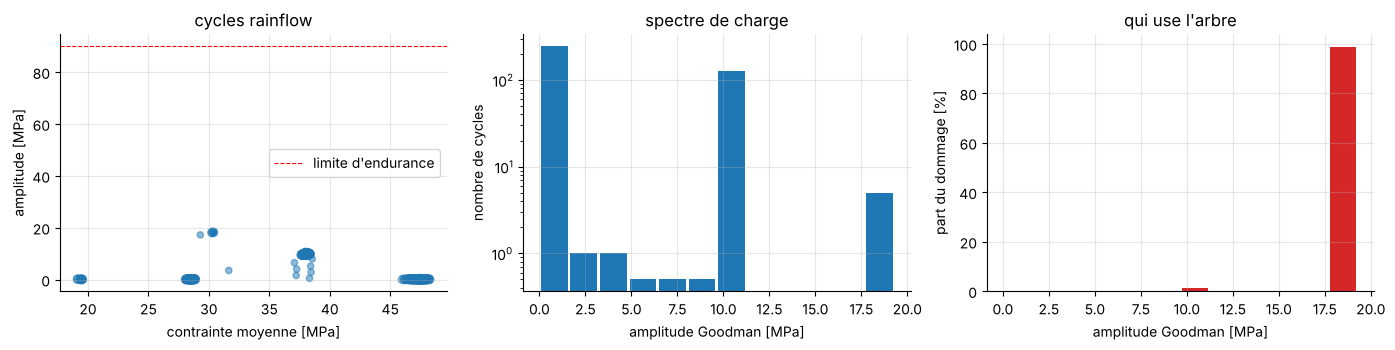

In [10]:
r = res["non lineaire"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].scatter(r.cycles.moyenne / 1e6, r.cycles.amplitude / 1e6, s=6 + 30 * r.cycles.compte, alpha=0.5)
ax[0].set_xlabel("contrainte moyenne [MPa]"); ax[0].set_ylabel("amplitude [MPa]")
ax[0].axhline(COURBE_ACIER_ARBRE.S_D / 1e6, color="r", ls="--", lw=0.8, label="limite d'endurance")
ax[0].set_title("cycles rainflow"); ax[0].legend()
b, n, d = r.histogramme(12)
centres = 0.5 * (b[1:] + b[:-1]) / 1e6
ax[1].bar(centres, n, width=(b[1] - b[0]) / 1e6 * 0.9); ax[1].set_yscale("log")
ax[1].set_xlabel("amplitude Goodman [MPa]"); ax[1].set_ylabel("nombre de cycles"); ax[1].set_title("spectre de charge")
ax[2].bar(centres, d / max(d.sum(), 1e-300) * 100, width=(b[1] - b[0]) / 1e6 * 0.9, color="C3")
ax[2].set_xlabel("amplitude Goodman [MPa]"); ax[2].set_ylabel("part du dommage [%]"); ax[2].set_title("qui use l'arbre")
plt.tight_layout(); plt.show()

## 6. Perte du reseau amont et reprise de charge par le groupe

Le scenario de reference, non lineaire seul (la topologie change) : le site est alimente
par le reseau avec le groupe en attente, a vide. A `t = 60 s` le reseau amont est perdu.

* la **batterie** prend la charge une seconde avant l'ouverture de la liaison (dans un
  site reel, elle la prend en quelques millisecondes ; le groupe n'est couple que 10 s
  apres, a vide) : les diodes se bloquent ;
* a `t = 60 s` la liaison `L_AMONT` s'ouvre : le site est isole ;
* a `t = 75 s` la consigne de tension de la batterie redescend en 60 s : le redresseur,
  alimente par le groupe, **reprend la charge progressivement** — la reprise echelonnee
  d'un groupe de secours.

On isole ensuite l'effet de la **vitesse de reprise** : a charge IT constante, une
reprise de 5 s contre une de 60 s.

In [11]:
t_tr = np.arange(0.0, DUREE_TRANSITION + DT / 2, DT)
P_tr = courbe_charge_ia(t_tr, P_moy=0.30, amplitude=0.25, periode=4.0, t_debut=20.0,
                        rampe=15.0, intervalle_ckpt=120.0, duree_ckpt=6.0, profondeur_ckpt=0.6)

def simuler_transition(duree_reprise, P=None):
    net_t = reseau_datacenter()
    m_t = ModeleNonLineaire(net_t)
    sc = scenario_perte_reseau(m_t, t_tr, P_tr if P is None else P, t_perte=60.0, t_reprise=75.0,
                               duree_reprise=duree_reprise)
    t0 = time.time()
    tr = m_t.simuler((0, DUREE_TRANSITION), uext_fn=sc.uext, t_eval=t_tr, rtol=1e-4, atol=1e-6,
                     sorties=["GE.C_arbre", "GE.P", "GE.Omega"])
    print(f"reprise en {duree_reprise:g} s : {time.time() - t0:.0f} s de calcul, {tr.n_solves} resolutions, "
          f"basculements : {[(round(b[0], 2), b[1], b[2], b[3]) for b in tr.basculements]}")
    return tr, sc

tr_60, sc_60 = simuler_transition(60.0)

reprise en 60 s : 117 s de calcul, 158627 resolutions, basculements : []


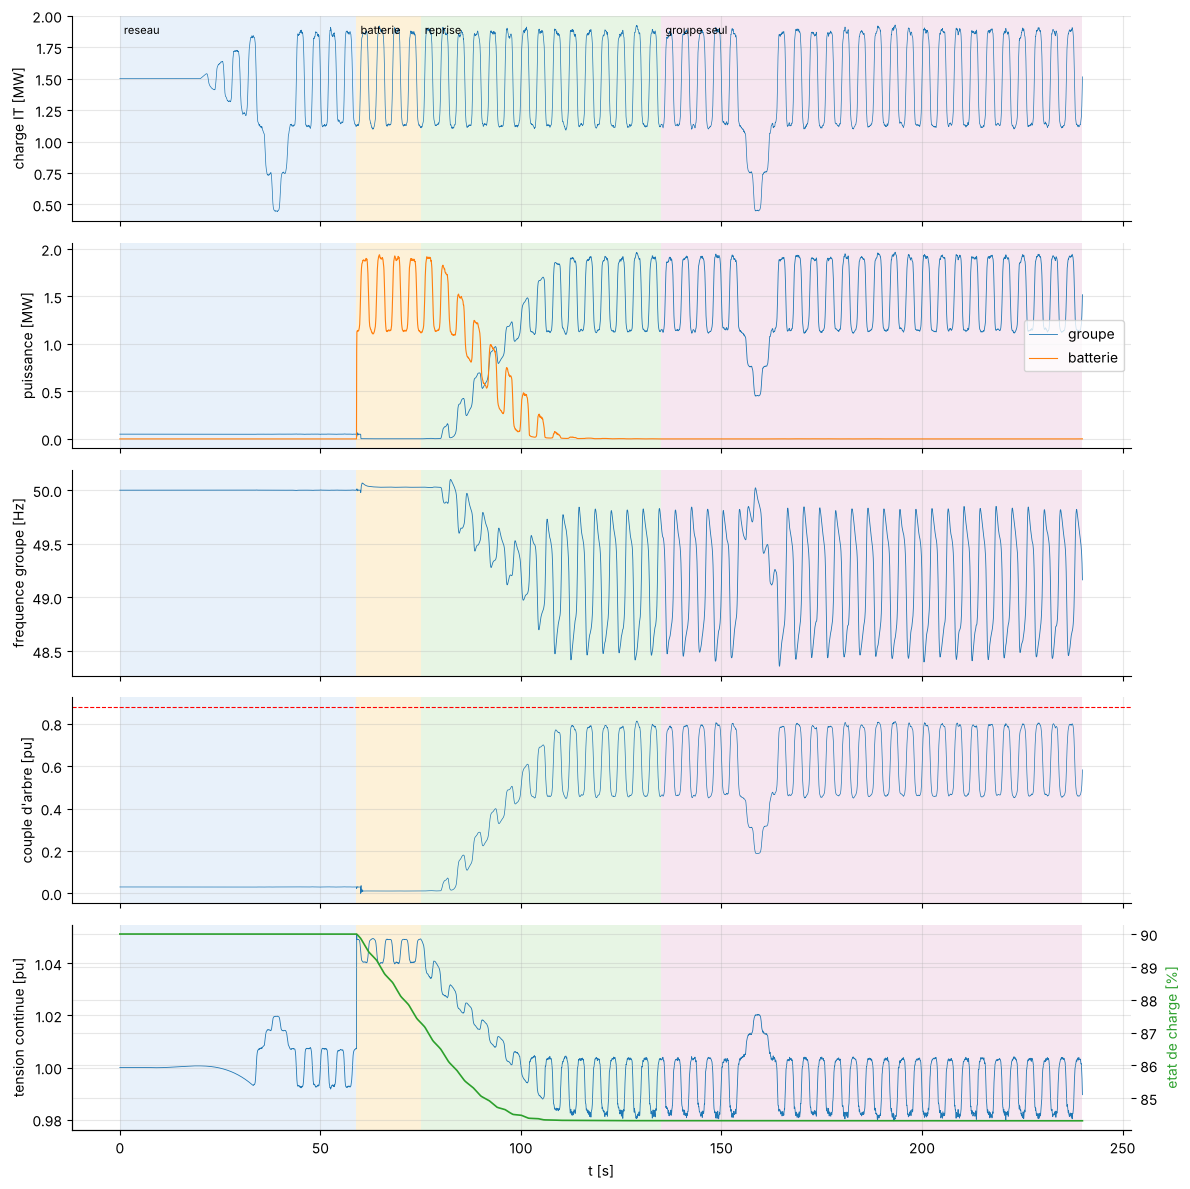

In [12]:
fig, ax = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
phases = [(0, 59, "reseau"), (59, 75, "batterie"), (75, 135, "reprise"), (135, DUREE_TRANSITION, "groupe seul")]
coul = ["#e8f1fa", "#fdf1d8", "#e7f5e4", "#f6e6f0"]
for a in ax:
    for (a0, a1, _), c in zip(phases, coul):
        a.axvspan(a0, a1, color=c, lw=0)
ax[0].plot(t_tr, P_tr * 5, lw=0.5); ax[0].set_ylabel("charge IT [MW]")
ax[1].plot(t_tr, tr_60.sorties["GE.P"] * 2.5, lw=0.6, label="groupe")
ax[1].plot(t_tr, tr_60.etat("BAT.i") * tr_60.etat("bus10.v") * 5, lw=0.8, label="batterie")
ax[1].set_ylabel("puissance [MW]"); ax[1].legend(loc="center right")
ax[2].plot(t_tr, tr_60.sorties["GE.Omega"] * 50, lw=0.6); ax[2].set_ylabel("frequence groupe [Hz]")
ax[3].plot(t_tr, tr_60.sorties["GE.C_arbre"], lw=0.5); ax[3].set_ylabel("couple d'arbre [pu]")
ax[3].axhline(0.88, color="r", ls="--", lw=0.8)
ax[4].plot(t_tr, tr_60.etat("bus10.v"), lw=0.6, label="tension continue [pu]")
ax4b = ax[4].twinx(); ax4b.plot(t_tr, tr_60.etat("BAT.soc") * 100, color="C2", lw=1.2); ax4b.set_ylabel("etat de charge [%]", color="C2")
ax[4].set_ylabel("tension continue [pu]"); ax[4].set_xlabel("t [s]")
for (a0, a1, lab) in phases: ax[0].text(a0 + 1, ax[0].get_ylim()[1] * 0.97, lab, fontsize=8, va="top")
plt.tight_layout(); plt.show()

In [13]:
def fatigue_phases(tr, label):
    out = {}
    for nom, (a0, a1) in {"reprise": (75.0, 135.0), "groupe seul": (135.0, DUREE_TRANSITION), "total (>= 60 s)": (60.0, DUREE_TRANSITION)}.items():
        k = (t_tr >= a0) & (t_tr <= a1)
        r = evaluer_fatigue(t_tr[k], tr.sorties["GE.C_arbre"][k], SN_GROUPE, seuil_pu=2e-3)
        out[nom] = {"couple max [pu]": tr.sorties["GE.C_arbre"][k].max(), "couple min [pu]": tr.sorties["GE.C_arbre"][k].min(),
                    "plus gros cycle [MPa]": r.amplitude_max / 1e6, "cycles": r.n_cycles, "dommage": r.dommage,
                    "marge d'amplitude (25 ans)": r.marge_amplitude()}
    return pd.DataFrame(out).T

print("Reprise en 60 s :")
display(fatigue_phases(tr_60, "60 s"))

Reprise en 60 s :


,couple max [pu],couple min [pu],plus gros cycle [MPa],cycles,dommage,marge d'amplitude (25 ans)
reprise,0.812621,0.010834,24.414118,25.5,1.876001e-14,3.223450
groupe seul,0.810599,0.187129,18.984426,72.5,1.534479e-15,4.079927
total (>= 60 s),0.812621,-0.000824,24.769094,101.0,2.411387e-14,3.440609


reprise en 5 s : 130 s de calcul, 175177 resolutions, basculements : []


reprise en 60 s : 121 s de calcul, 165303 resolutions, basculements : []


,reprise en 5 s,reprise en 60 s
couple final [pu],0.6234,0.6234
couple max [pu],0.6292,0.6234
depassement [pu],0.0058,0.0000
frequence min [Hz],48.5423,49.1328
plus gros cycle [MPa],18.8239,18.6481
cycles,1.0000,0.5000


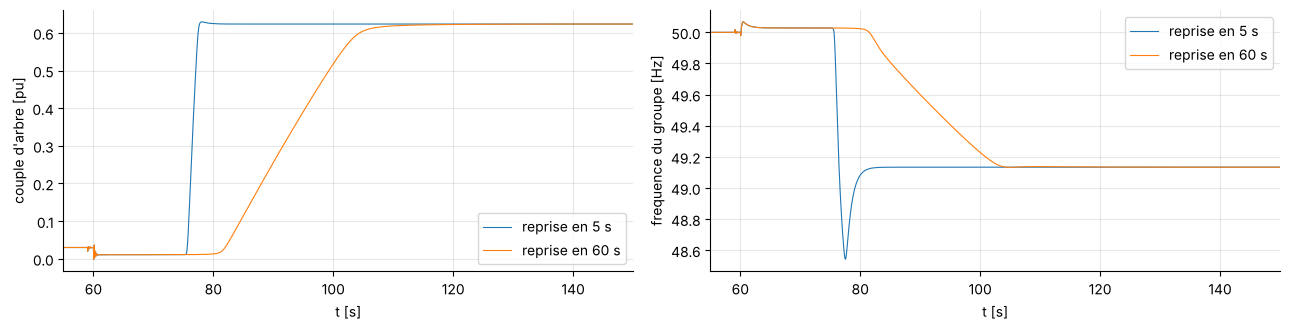

In [14]:
P_cst = np.full_like(t_tr, 0.30)   # charge IT constante : on ne voit que la reprise
tr_c5, _ = simuler_transition(5.0, P_cst)
tr_c60, _ = simuler_transition(60.0, P_cst)

def bilan_reprise(tr):
    C = tr.sorties["GE.C_arbre"]; w_ = tr.sorties["GE.Omega"]
    k = (t_tr >= 70) & (t_tr <= DUREE_TRANSITION)
    plateau = C[(t_tr >= DUREE_TRANSITION - 10)].mean()
    r_ = evaluer_fatigue(t_tr[k], C[k], SN_GROUPE, seuil_pu=2e-3)
    return {"couple final [pu]": plateau, "couple max [pu]": C[k].max(), "depassement [pu]": C[k].max() - plateau,
            "frequence min [Hz]": w_[k].min() * 50, "plus gros cycle [MPa]": r_.amplitude_max / 1e6,
            "cycles": r_.n_cycles}

comp = pd.DataFrame({"reprise en 5 s": bilan_reprise(tr_c5), "reprise en 60 s": bilan_reprise(tr_c60)})
display(comp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for tr, lab in [(tr_c5, "reprise en 5 s"), (tr_c60, "reprise en 60 s")]:
    ax[0].plot(t_tr, tr.sorties["GE.C_arbre"], lw=0.8, label=lab)
    ax[1].plot(t_tr, tr.sorties["GE.Omega"] * 50, lw=0.8, label=lab)
ax[0].set_ylabel("couple d'arbre [pu]"); ax[1].set_ylabel("frequence du groupe [Hz]")
for a in ax: a.set_xlim(55, 150); a.set_xlabel("t [s]"); a.legend()
plt.tight_layout(); plt.show()

## 7. Balayages avec le modele linearise

Le linearise du site isole (section 4) permet de poser des questions que le non lineaire
rend trop cheres : une simulation de 10 minutes y coute 0,1 s.

**Reponse en frequence** — le gain de la charge IT vers le couple d'arbre est la carte
des frequences de variation dangereuses. Une charge qui oscille a la frequence du mode
electromecanique du groupe ou de la torsion y est amplifiee.

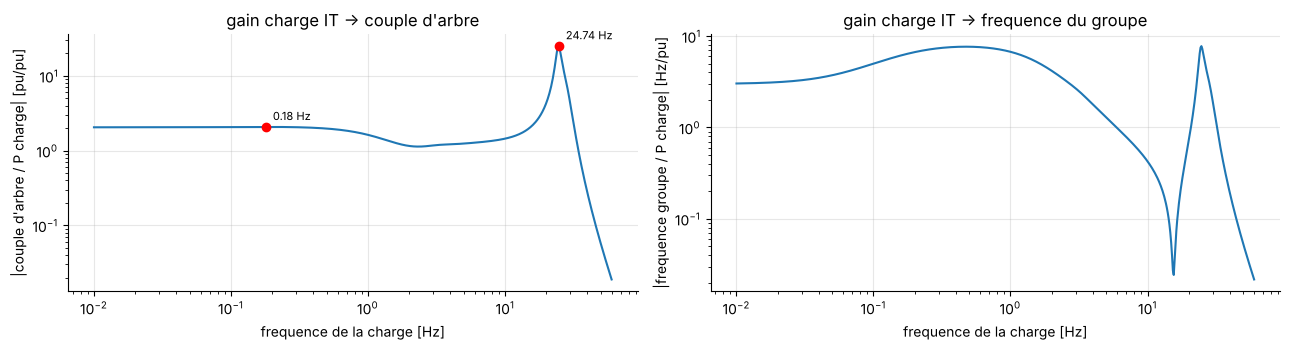

gain statique charge -> couple : 2.052 (la charge appelee dans la base du groupe vaut 2 : 5 MVA / 2,5 MVA)


In [15]:
dae = net_i.dae_lineaire()
f = np.logspace(-2, np.log10(60), 600)
H = dae.reponse_frequentielle(f, ["IT.p_ref"], ["GE.C_arbre"])[:, 0, 0]
H_w = dae.reponse_frequentielle(f, ["IT.p_ref"], ["GE.Omega"])[:, 0, 0]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].loglog(f, np.abs(H)); ax[0].set_xlabel("frequence de la charge [Hz]"); ax[0].set_ylabel("|couple d'arbre / P charge| [pu/pu]")
ax[0].set_title("gain charge IT -> couple d'arbre")
ax[1].loglog(f, np.abs(H_w) * 50); ax[1].set_xlabel("frequence de la charge [Hz]"); ax[1].set_ylabel("|frequence groupe / P charge| [Hz/pu]")
ax[1].set_title("gain charge IT -> frequence du groupe")
pics = [i for i in range(1, len(f) - 1) if np.abs(H[i]) > np.abs(H[i - 1]) and np.abs(H[i]) > np.abs(H[i + 1])]
for i in pics:
    ax[0].plot(f[i], np.abs(H[i]), "ro"); ax[0].annotate(f"{f[i]:.2f} Hz", (f[i], np.abs(H[i])), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.tight_layout(); plt.show()
print("gain statique charge -> couple :", round(abs(H[0]), 3), "(la charge appelee dans la base du groupe vaut 2 : 5 MVA / 2,5 MVA)")

**Fatigue en fonction de la periode des variations** — pour une charge qui oscille
sinusoidalement de +-25 % de sa valeur nominale a la frequence `f`, le couple d'arbre est
une sinusoide d'amplitude `|H(f)|.dP` ; la vie de l'arbre (comptage a la main :
`3600.f` cycles par heure) se lit directement sur la courbe S-N. Une charge informatique
n'oscille pas a 25 Hz : la courbe dit **quelle bande de frequences il ne faut pas laisser
exciter** (variations rapides de la charge, harmoniques du redresseur ramenes par la
regulation), pas ce que fait la charge.

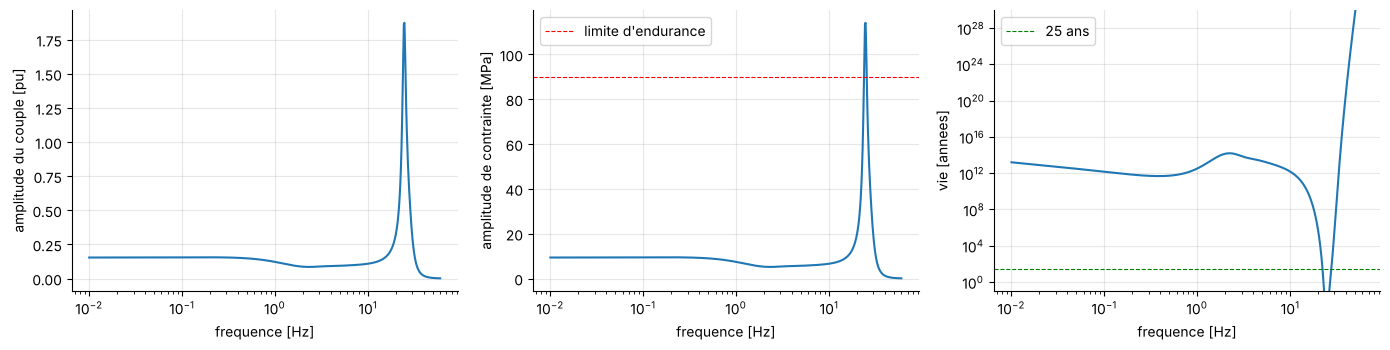

bande ou +-25 % de charge depasse la limite d'endurance : 24.0 a 25.1 Hz
pire frequence : 24.74 Hz, amplitude de contrainte 114.1 MPa (127 % de la limite d'endurance), vie 3.08e-04 ans


In [16]:
dP = 0.25 * 0.30                      # +-25 % de 0,30 pu
C0 = sortie(net_i, "GE", "C_arbre")   # couple moyen du groupe a l'equilibre
cb = couple_base(SN_GROUPE, 50.0, ARBRE_DEFAUT.paires_poles)
tau_m = tension_cisaillement(C0 * cb, ARBRE_DEFAUT.diametre_m)
amp_C = np.abs(H) * dP                # amplitude du couple [pu]
S_a = tension_cisaillement(amp_C * cb, ARBRE_DEFAUT.diametre_m)
S_eq = S_a / (1.0 - tau_m / ARBRE_DEFAUT.tau_u)
N_f = COURBE_ACIER_ARBRE.cycles_a_rupture(S_eq)
vie_h = N_f / (3600.0 * f)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].semilogx(f, amp_C); ax[0].set_ylabel("amplitude du couple [pu]"); ax[0].set_xlabel("frequence [Hz]")
ax[1].semilogx(f, S_a / 1e6); ax[1].axhline(COURBE_ACIER_ARBRE.S_D / 1e6, color="r", ls="--", lw=0.8, label="limite d'endurance")
ax[1].set_ylabel("amplitude de contrainte [MPa]"); ax[1].set_xlabel("frequence [Hz]"); ax[1].legend()
ax[2].loglog(f, vie_h / 8760.0); ax[2].axhline(25, color="g", ls="--", lw=0.8, label="25 ans"); ax[2].set_ylim(1e-1, 1e30)
ax[2].set_ylabel("vie [annees]"); ax[2].set_xlabel("frequence [Hz]"); ax[2].legend()
plt.tight_layout(); plt.show()
au_dessus = f[S_a > COURBE_ACIER_ARBRE.S_D]
if len(au_dessus):
    print(f"bande ou +-25 % de charge depasse la limite d'endurance : {au_dessus.min():.1f} a {au_dessus.max():.1f} Hz")
i = np.argmax(S_a)
print(f"pire frequence : {f[i]:.2f} Hz, amplitude de contrainte {S_a[i] / 1e6:.1f} MPa "
      f"({100 * S_a[i] / COURBE_ACIER_ARBRE.S_D:.0f} % de la limite d'endurance), vie {vie_h[i] / 8760:.2e} ans")

**Leviers** — lissage par la batterie (`Kh` : la batterie n'absorbe que la composante
rapide de la charge), amortissement de l'accouplement (`zeta_tors`) et amplitude des
variations de la charge. Chaque point est un site reconstruit et une simulation lineaire
de la meme courbe de 10 minutes.

In [17]:
def evaluer_variante(label, courbe_P=P_it, **kw):
    n = reseau_datacenter(reseau_amont=False, **kw)
    mm = ModeleNonLineaire(n)
    sc = mm.scenario(Courbe("IT.p_ref", t_ilot, courbe_P))
    tl = simuler_lineaire(mm, t_ilot, sc, sorties=["GE.C_arbre", "GE.Omega"])
    C = tl.sorties["GE.C_arbre"]
    r = evaluer_fatigue(t_ilot[fen], C[fen], SN_GROUPE, seuil_pu=2e-3)
    return {"variante": label, "couple crete a crete [pu]": np.ptp(C[fen]),
            "plus gros cycle [MPa]": r.amplitude_max / 1e6,
            "frequence min [Hz]": tl.sorties["GE.Omega"][fen].min() * 50,
            "dommage par heure": r.dommage_par_heure, "marge d'amplitude (25 ans)": r.marge_amplitude()}

lignes = [evaluer_variante("reference")]
for kh in (5.0, 20.0, 60.0):
    lignes.append(evaluer_variante(f"lissage batterie Kh = {kh:g}", lissage=kh))
for z in (0.01, 0.1):
    lignes.append(evaluer_variante(f"amortissement de torsion = {z}", zeta_tors=z))
for a in (0.1, 0.4):
    Pa = courbe_charge_ia(t_ilot, P_moy=0.30, amplitude=a, periode=4.0, t_debut=20.0, rampe=15.0,
                          intervalle_ckpt=120.0, duree_ckpt=6.0, profondeur_ckpt=0.6)
    lignes.append(evaluer_variante(f"amplitude de la charge = {a:g}", courbe_P=Pa))
for per in (1.0, 12.0):
    Pp = courbe_charge_ia(t_ilot, P_moy=0.30, amplitude=0.25, periode=per, t_debut=20.0, rampe=15.0,
                          intervalle_ckpt=120.0, duree_ckpt=6.0, profondeur_ckpt=0.6)
    lignes.append(evaluer_variante(f"periode de la charge = {per:g} s", courbe_P=Pp))
leviers = pd.DataFrame(lignes).set_index("variante")
display(leviers)

,couple crete a crete [pu],plus gros cycle [MPa],frequence min [Hz],dommage par heure,marge d'amplitude (25 ans)
variante,,,,,
reference,0.612130,18.639128,49.224321,3.443509e-14,4.215139
lissage batterie Kh = 5,0.527472,16.061346,49.510568,4.617871e-15,4.919623
lissage batterie Kh = 20,0.364655,11.103617,49.808775,4.027451e-17,7.085135
lissage batterie Kh = 60,0.206611,6.291217,49.917455,2.722891e-20,12.422079
amortissement de torsion = 0.01,0.612195,18.641127,49.224416,3.455952e-14,4.213970
amortissement de torsion = 0.1,0.611810,18.629398,49.224220,3.424993e-14,4.216888
amplitude de la charge = 0.1,0.478153,14.559592,49.628310,1.327750e-15,5.414673
amplitude de la charge = 0.4,0.746166,22.720493,48.820333,5.873212e-13,3.388850
periode de la charge = 1 s,0.599597,18.257509,48.956763,2.564646e-14,4.311774


## 8. Ce qu'il faut retenir

Le tableau final rassemble les resultats ; les limites du modele sont a lire avec eux.

In [18]:
resume = pd.DataFrame({
    "valeur": {
        "couple d'arbre moyen en ilot [pu]": sortie(net_i, "GE", "C_arbre"),
        "couple d'arbre max, ilot 10 min, non lineaire [pu]": tr_nl.sorties["GE.C_arbre"].max(),
        "butee moteur Fmax [pu]": ge_i.pdict["Fmax"],
        "plus gros cycle, ilot 10 min [MPa]": res["non lineaire"].amplitude_max / 1e6,
        "marge d'amplitude 25 ans, ilot 10 min": res["non lineaire"].marge_amplitude(),
        "plus gros cycle, reprise 60 s avec oscillations de charge [MPa]": evaluer_fatigue(t_tr[t_tr >= 75], tr_60.sorties["GE.C_arbre"][t_tr >= 75], SN_GROUPE, seuil_pu=2e-3).amplitude_max / 1e6,
        "depassement du couple a la reprise en 5 s, charge constante [pu]": comp.loc["depassement [pu]", "reprise en 5 s"],
        "depassement du couple a la reprise en 60 s, charge constante [pu]": comp.loc["depassement [pu]", "reprise en 60 s"],
        "frequence minimale du groupe, ilot [Hz]": tr_nl.sorties["GE.Omega"].min() * 50,
        "etat de charge de la batterie en fin de reprise [%]": tr_60.etat("BAT.soc")[-1] * 100,
    }
})
display(resume.round(3))

,valeur
couple d'arbre moyen en ilot [pu],0.621
"couple d'arbre max, ilot 10 min, non lineaire [pu]",0.799
butee moteur Fmax [pu],0.880
"plus gros cycle, ilot 10 min [MPa]",18.321
"marge d'amplitude 25 ans, ilot 10 min",4.281
"plus gros cycle, reprise 60 s avec oscillations de charge [MPa]",24.414
"depassement du couple a la reprise en 5 s, charge constante [pu]",0.006
"depassement du couple a la reprise en 60 s, charge constante [pu]",0.000
"frequence minimale du groupe, ilot [Hz]",49.225
etat de charge de la batterie en fin de reprise [%],84.311


**Limites a garder en tete**

* **Modele moyen dq** : pas de pulsation d'allumage des cylindres ni d'harmonique 6 du
  redresseur dans le couple electrique. Ces composantes de haute frequence ajoutent des
  cycles nombreux et petits ; elles se superposent par l'entree `GE.dT_exc` (couple
  moteur additionnel) a l'amplitude et la frequence a tester.
* **Donnees materiau** : la courbe S-N et l'arbre sont des ordres de grandeur ; seules les
  *comparaisons* (reprise lente ou rapide, lissage, amortissement) sont robustes. Les
  parametres du groupe (`GROUPE_DEFAULT`) sont ceux d'un groupe de 2,5 MVA type, pas ceux
  d'un constructeur.
* **Charge IT** : le profil est synthetique. Le remplacer par une mesure
  (`Courbe("IT.p_ref", t, P)`) ne change rien d'autre.
* **Sequence de reprise** : le groupe est couple en attente des le depart (le modele n'a
  pas de manoeuvre de fermeture) ; la batterie prend la charge avant l'ouverture de la
  liaison, ce qui transpose l'ordre reel (batterie d'abord, groupe ensuite).
* **Regle de Miner** : lineaire, elle ignore l'ordre des cycles ; le coude de la courbe
  S-N (pente de Haibach) est un modele.
* **Diodes** : caracteristique lisse (`eps_v`), pas de conduction discontinue.